# Day 4 · 실습 1. Self-Attention에서 Transformer Encoder Block까지

이번 실습은 **Self-Attention이 토큰 간 정보를 결합하는 과정**과 **FFN이 각 토큰의 특징을 변환하는 과정**을 직접 확인합니다.

- **A형:** 입력·위치 정보 → Q, K, V → Self-Attention → 가중치 시각화 → FFN과 Encoder Block
- **B형 1단계:** A형을 참고해 Attention 가중치 계산하기 (1문제)
- **B형 2단계:** A형의 핵심 연산을 조합해 Self-Attention 함수 완성하기 (1문제)

이번에는 **단일 Attention Head로 구성한 간소화된 Encoder Block**을 사용합니다. Multi-Head Attention, Mask, Dropout과 Decoder는 다루지 않습니다. **가중치를 학습하지 않은 상태이므로 Attention 수치를 단어의 실제 의미 관계로 해석하지 않습니다.** GPU나 별도의 가중치 파일은 필요하지 않습니다.

## A형 · Self-Attention과 Transformer Encoder Block 이해하기

### A-1. 입력 토큰과 위치 정보 준비

Transformer는 입력 토큰의 **임베딩 벡터에 위치 정보를 더해** 각 토큰을 표현합니다.

**아래 코드에서 다음 두 가지를 확인하세요.**

1. **토큰 임베딩:** 각 토큰 ID를 특징 벡터로 변환합니다.
2. **위치 임베딩:** 토큰이 놓인 순서의 정보를 같은 차원의 벡터로 만들어 더합니다.

이번 실습은 `A B C`라는 세 개의 토큰과 작은 4차원 벡터를 사용합니다. 위치 벡터도 학습 전의 예시 값입니다.

In [1]:
# 1. 실습 환경 준비

import math
import torch
from torch import nn
import matplotlib.pyplot as plt

# 실행할 때마다 동일한 난수가 생성되도록 설정합니다.
torch.manual_seed(42)

# 작은 모델을 CPU에서 실행하므로 연산 스레드를 1개로 설정합니다.
torch.set_num_threads(1)

# Tensor 출력 시 소수점 셋째 자리까지 표시합니다.
torch.set_printoptions(precision=3, sci_mode=False)


# 2. 입력 토큰 준비

# 계산 원리를 확인하기 위해 "나는", "커피를", "마신다" 세 개의 토큰을 사용합니다.
tokens = ["나는", "커피를", "마신다"]

# 각 토큰에 고유한 정수 ID를 부여합니다.
# 예: "나는" → 0, "커피를" → 1, "마신다" → 2
token_to_id = {token: i for i, token in enumerate(tokens)}

# 문자열 토큰을 정수 ID Tensor로 변환합니다.
# [[0, 1, 2]] : 문장 1개에 토큰 3개
token_ids = torch.tensor(
    [[token_to_id[token] for token in tokens]],
    dtype=torch.long
)

# 각 토큰의 위치를 나타내는 ID를 생성합니다.
# "나는"는 0번째, "커피를"는 1번째, "마신다"는 2번째 위치입니다.
position_ids = torch.arange(len(tokens)).unsqueeze(0)

# 각 토큰을 표현할 임베딩 벡터의 차원을 4로 설정합니다.
d_model = 4

# 3. 토큰 임베딩과 위치 임베딩 계층 생성

# 토큰 ID를 4차원 벡터로 변환하는 Embedding 계층
token_embedding = nn.Embedding(len(tokens), d_model)

# 각 토큰의 위치 ID를 4차원 벡터로 변환하는 Embedding 계층
# Transformer는 토큰의 순서를 별도로 알려주어야 하므로 위치 정보를 사용합니다.
position_embedding = nn.Embedding(len(tokens), d_model)


# 4. 토큰 임베딩과 위치 임베딩 계산

# 각 토큰을 의미나 특징을 표현하는 4차원 벡터로 변환합니다.
token_vectors = token_embedding(token_ids)

# 각 토큰의 위치를 나타내는 4차원 벡터를 가져옵니다.
position_vectors = position_embedding(position_ids)


# 5. Transformer의 최종 입력 벡터 생성

########## 핵심 : 토큰 임베딩에 위치 임베딩을 더합니다.
# 이를 통해 각 토큰의 특징과 위치 정보가 하나의 벡터에 함께 반영됩니다.
# 두 벡터의 차원이 같아야 원소별 덧셈이 가능합니다.
x = token_vectors + position_vectors


# 6. 결과 확인

print("토큰:", tokens)

# A 토큰의 임베딩 벡터
print("A의 토큰 임베딩:", token_vectors[0, 0].detach())

# A 토큰이 첫 번째 위치에 있다는 정보를 표현한 벡터
print("A의 위치 임베딩:", position_vectors[0, 0].detach())

# 토큰 임베딩과 위치 임베딩을 더한 최종 입력 벡터
# 이 벡터가 이후 Self-Attention 계층에 전달됩니다.
print("A의 최종 입력  :", x[0, 0].detach())

토큰: ['나는', '커피를', '마신다']
A의 토큰 임베딩: tensor([0.337, 0.129, 0.234, 0.230])
A의 위치 임베딩: tensor([ 1.110, -1.690, -0.989,  0.958])
A의 최종 입력  : tensor([ 1.447, -1.561, -0.754,  1.188])


### A-2. 입력 벡터에서 Q, K, V 생성하기

Self-Attention에서는 같은 입력 벡터를 **서로 다른 Linear 계층**에 통과시켜 Query(Q), Key(K), Value(V)를 만듭니다.

**아래 코드에서 다음 세 가지 역할을 구분하세요.**

1. **Query(Q):** 현재 토큰이 어떤 정보를 참고할지 비교하는 기준입니다.
2. **Key(K):** 다른 토큰의 정보와 비교할 때 사용하는 벡터입니다.
3. **Value(V):** Attention 가중치에 따라 실제로 결합할 정보입니다.

세 Linear 계층은 각각 별도의 가중치를 가집니다. 여기서는 학습 전 가중치로 계산 과정만 관찰합니다.

In [2]:
# 1. Q, K, V를 생성하는 Linear 계층 정의

# Self-Attention에서는 같은 입력 벡터(x)에서 Q, K, V를 각각 생성합니다.
# 세 벡터는 역할이 다르므로 서로 다른 가중치를 가진 Linear 계층을 사용합니다. -> 입력 벡터를 Query, Key, Value 벡터로 변환하는 Linear 계층

# Query(Q): 현재 토큰이 다른 토큰에서 어떤 정보를 찾을지 표현합니다.
q_proj = nn.Linear(d_model, d_model, bias=False)

# Key(K): 다른 토큰이 참고할 수 있도록 자신의 특징을 표현합니다.
k_proj = nn.Linear(d_model, d_model, bias=False)

# Value(V): Attention을 통해 실제로 전달할 정보를 표현합니다.
v_proj = nn.Linear(d_model, d_model, bias=False)


# 2. 입력 벡터를 Q, K, V로 변환

######### 핵심: 같은 입력 x에 서로 다른 Linear 변환을 적용합니다.
# 이를 통해 각 토큰에서 서로 다른 역할을 가진 Q, K, V 벡터가 만들어집니다.
Q = q_proj(x)
K = k_proj(x)
V = v_proj(x)


# 3. Q, K, V의 결과 확인

# 이번 실습에서는 입력과 출력 차원을 모두 4로 설정했습니다.
# 따라서 Q, K, V는 각각 (문장 수 1, 토큰 수 3, 벡터 차원 4) 형태입니다.
print("Q, K, V의 Shape:", tuple(Q.shape), tuple(K.shape), tuple(V.shape))

# A 토큰에서 생성된 Q, K, V 벡터를 비교합니다.
# 같은 입력에서 출발했지만 서로 다른 가중치를 사용하므로 값이 달라집니다.
print("A 토큰의 Q:", Q[0, 0].detach())
print("A 토큰의 K:", K[0, 0].detach())
print("A 토큰의 V:", V[0, 0].detach())

Q, K, V의 Shape: (1, 3, 4) (1, 3, 4) (1, 3, 4)
A 토큰의 Q: tensor([ 0.987, -1.058, -0.475,  0.257])
A 토큰의 K: tensor([-0.281, -0.107,  1.250, -0.444])
A 토큰의 V: tensor([-0.282, -0.053, -0.834, -0.143])


### A-3. Self-Attention으로 토큰 간 정보 결합하기

각 토큰의 Q와 모든 토큰의 K를 비교해 **Attention 점수**를 계산한 뒤, Softmax로 가중치를 만듭니다. 마지막으로 이 가중치를 V에 적용하여 각 토큰의 새로운 표현을 얻습니다.

**아래 코드에서 세 가지를 확인하세요.**

1. **Q·K 비교:** 토큰 사이의 Attention 점수를 계산합니다.
2. **Softmax:** 토큰별 가중치가 0~1 사이이고 한 행의 합이 1이 되도록 만듭니다.
3. **V의 가중합:** 각 토큰이 다른 토큰의 정보를 반영해 새 벡터를 얻습니다.

In [3]:
# Q 벡터의 차원 수를 가져옵니다. 이번 실습에서는 4입니다.
d_k = Q.size(-1)

########### 핵심: Q와 K의 내적을 계산하여 토큰 간 Attention 점수를 구합니다.
# K의 마지막 두 차원을 전치해 (3, 4) → (4, 3)으로 바꿉니다.
# Q(3, 4) × Kᵀ(4, 3) → 토큰 간 Attention 점수(3, 3)
# 점수가 지나치게 커지지 않도록 sqrt(d_k)로 나눕니다.
scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(d_k)

########## 핵심 : 마지막 차원(참고할 토큰들)에 Softmax를 적용해 가중치를 만듭니다.
weights = torch.softmax(scores, dim=-1)

########## 핵심 : 가중치를 V에 적용해 다른 토큰의 정보를 결합합니다.
attention_output = torch.matmul(weights, V)

print("Attention 가중치 (행: Query / 열: Key)")
print(weights[0].detach())
print("각 Query의 가중치 합:", weights.sum(dim=-1).detach())
print("Attention 출력 Shape:", tuple(attention_output.shape))

Attention 가중치 (행: Query / 열: Key)
tensor([[0.187, 0.447, 0.366],
        [0.564, 0.172, 0.264],
        [0.342, 0.333, 0.325]])
각 Query의 가중치 합: tensor([[1., 1., 1.]])
Attention 출력 Shape: (1, 3, 4)


### A-4. Attention 가중치 시각화하기

Attention 가중치의 **행은 정보를 참고하는 토큰(Query)**, **열은 참고 대상 토큰(Key)**을 나타냅니다.

**아래 그림에서 다음 두 가지를 확인하세요.**

1. 한 행의 값은 각 참고 대상 토큰에 부여한 가중치이며, 합은 1입니다.
2. 가중치를 이용해 Value를 결합하므로, 각 토큰의 출력은 다른 토큰의 정보를 반영할 수 있습니다.

*현재 가중치는 학습 전 값입니다. 그림의 색이나 숫자가 실제 문장의 의미 관계를 나타내지는 않습니다.*

findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
C:\Users\kjm05\AppData\Local\Temp\ipykernel_9628\4167201256.py:22: UserWarning: Glyph 45208 (\N{HANGUL SYLLABLE NA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\kjm05\AppData\Local\Temp\ipykernel_9628\4167201256.py:22: UserWarning: Glyph 45716 (\N{HANGUL SYLLABLE NEUN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
C:\Users\kjm05\AppData\Local\Temp\ipykernel_9628\4167201256.py:22: UserWarning: Glyph 52964 (\N{HANGUL SYLLABLE KEO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\kjm05\AppData\Local\Temp\ipykernel_9628\4167201256.py:22: UserWarning: Glyph 54588 (\N{HANGUL SYLLABLE PI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\kjm05\AppData\Local\Temp\ipykernel_9628\4167201256.py:22: UserWarning: Glyph 47484 (\N{HANGUL SYLLABLE REUL}) mi

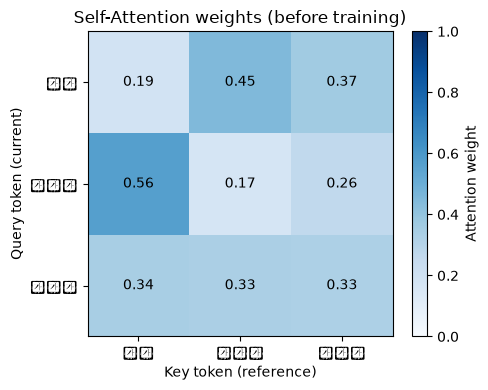

In [4]:
# 한글 폰트가 깨지지 않도록 설정합니다.
plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

# 행: 현재 토큰(Query), 열: 참고할 토큰(Key)
weight_matrix = weights[0].detach().cpu().numpy()
fig, ax = plt.subplots(figsize=(5, 4))
img = ax.imshow(weight_matrix, cmap="Blues", vmin=0, vmax=1)

ax.set_xticks(range(len(tokens)), labels=tokens)
ax.set_yticks(range(len(tokens)), labels=tokens)
ax.set_xlabel("Key token (reference)")
ax.set_ylabel("Query token (current)")
ax.set_title("Self-Attention weights (before training)")

# 각 칸에 실제 Attention 가중치를 함께 표시합니다.
for row in range(len(tokens)):
    for col in range(len(tokens)):
        ax.text(col, row, f"{weight_matrix[row, col]:.2f}", ha="center", va="center")

fig.colorbar(img, ax=ax, label="Attention weight", fraction=0.045)
plt.tight_layout()
plt.show()

### A-5. FFN과 Transformer Encoder Block 이해하기

Self-Attention은 **토큰 사이의 정보를 결합**합니다. 그다음 FFN은 **각 토큰의 특징을 독립적으로 변환**합니다.

**아래 코드에서 다음 세 가지를 확인하세요.**

1. **Residual + LayerNorm:** Attention 결과에 원래 입력을 더하고 정규화합니다.
2. **FFN:** 같은 신경망을 각 토큰에 독립적으로 적용하며, `4 → 8 → 4`차원으로 특징을 변환합니다.
3. **Block 출력:** FFN 결과에도 Residual + LayerNorm을 적용해 다음 Block에 전달할 표현을 만듭니다.

이 셀은 **단일 Head를 사용한 간소화된 Encoder Block**입니다. 여기서 FFN은 최종 단어 분류용 Linear 계층이 아니라 **토큰의 특징을 변환하는 계층**입니다.

In [5]:
# Self-Attention과 FFN 각각에 Residual 연결과 LayerNorm을 적용합니다.
norm1 = nn.LayerNorm(d_model)
norm2 = nn.LayerNorm(d_model)
d_ff = 8

# FFN은 모든 토큰에 같은 가중치를 적용하지만 토큰 사이를 섞지는 않습니다.
ffn = nn.Sequential(
    nn.Linear(d_model, d_ff),
    nn.ReLU(),
    nn.Linear(d_ff, d_model),
)

# 1. Attention 결과에 입력 x를 더한 뒤 정규화합니다.
after_attention = norm1(x + attention_output)

# 2. FFN은 각 토큰의 특징을 넓혔다가 다시 모델 차원으로 변환합니다.
ffn_hidden = ffn[1](ffn[0](after_attention))
ffn_output = ffn[2](ffn_hidden)

# 3. FFN 결과에도 원래 입력을 더한 뒤 정규화합니다.
block_output = norm2(after_attention + ffn_output)

# 같은 토큰을 따로 넣어도 FFN의 결과가 같은지 확인합니다.
single_token_output = ffn(after_attention[:, :1, :])

print("Attention 이후:", tuple(after_attention.shape))
print("FFN 중간 표현:", tuple(ffn_hidden.shape))
print("FFN 출력     :", tuple(ffn_output.shape))
print("Encoder Block 최종 출력:", tuple(block_output.shape))
print("FFN의 토큰별 독립 처리:", torch.allclose(ffn_output[:, :1, :], single_token_output))

Attention 이후: (1, 3, 4)
FFN 중간 표현: (1, 3, 8)
FFN 출력     : (1, 3, 4)
Encoder Block 최종 출력: (1, 3, 4)
FFN의 토큰별 독립 처리: True


## B형 1단계 · Attention 가중치 계산하기

A-3에서 배운 연산을 활용하여 **Q와 K로 Attention 가중치를 계산하는 함수**를 완성하세요.

- **구현 범위:** Attention 점수 계산 → Softmax 적용 (핵심 코드 2줄)
- 입력 Q, K와 차원 크기 `d_k`는 준비되어 있습니다. A형 코드를 참고해 그대로 작성할 수 있습니다.

In [6]:
def calc_attention_weights(q, k):
    d_k = q.size(-1)
    
    scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(d_k)
    weights = torch.softmax(scores, dim=-1)

    return weights

In [7]:
# 결과 확인 코드: 함수가 A형과 같은 Attention 가중치를 만드는지 검사합니다.
b1_weights = calc_attention_weights(Q, K)
assert torch.allclose(b1_weights, weights, atol=1e-6)
print("B형 1단계 통과: A형과 같은 Attention 가중치를 계산했습니다.")

B형 1단계 통과: A형과 같은 Attention 가중치를 계산했습니다.


## B형 2단계 · Self-Attention 함수 완성하기

A형에서 배운 **Attention 점수 계산 → Softmax → Value 가중합**을 조합하여 Self-Attention 함수를 완성하세요.

- **구현 범위:** 핵심 연산 3줄
- Q, K, V는 이미 준비되어 있습니다. 결과는 `output`과 `weights`로 반환합니다.
- 아직 배우지 않은 시각화·입출력 준비 코드는 구현하지 않아도 됩니다.

In [8]:
def self_attention(q, k, v):
    d_k = q.size(-1)
    
    scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(d_k)
    weights = torch.softmax(scores, dim=-1)
    output = torch.matmul(weights,v)
    
    return output, weights

In [9]:
# 결과 확인 코드: A형의 점수·가중합 결과와 같은지 검사합니다.
b2_output, b2_weights = self_attention(Q, K, V)
assert torch.allclose(b2_weights, weights, atol=1e-6)
assert torch.allclose(b2_output, attention_output, atol=1e-6)
print("B형 2단계 통과: Self-Attention 출력과 가중치가 모두 일치합니다.")

B형 2단계 통과: Self-Attention 출력과 가중치가 모두 일치합니다.


### 실습 마무리

이번 실습에서는 **Transformer Encoder Block이 입력 토큰의 정보를 결합하고 변환하는 과정**을 확인했습니다.

1. **위치 정보:** 토큰 임베딩에 위치 임베딩을 더해 입력을 만듭니다.
2. **Self-Attention:** Q·K로 가중치를 구하고, 그 가중치로 V의 정보를 결합합니다.
3. **FFN:** Attention으로 결합된 특징을 각 토큰별로 독립적으로 변환합니다.
4. **Encoder Block:** Attention과 FFN 각각에 Residual 연결과 LayerNorm을 적용합니다.

**핵심:** Self-Attention은 토큰 *사이*의 정보를 결합하고, FFN은 각 토큰 *내부*의 특징을 변환합니다.